# OCSMM-SHAP
## Handwritten letter recognition dataset

In [1]:
import pandas as pd
import numpy as np
from sklearn.datasets import fetch_openml

letters, y = fetch_openml("letter", version=1, return_X_y=True, parser="auto")

feature_names = letters.columns.tolist()
letters["group"] = y  # Add group labels (letters A-Z)

# Verify groups
print("Groups:", letters["group"].unique())  # ['A', 'B', ..., 'Z']
print("Samples per group:\n", letters["group"].value_counts())

Groups: ['Z', 'P', 'S', 'H', 'F', ..., 'T', 'C', 'G', 'B', 'J']
Length: 26
Categories (26, object): ['A', 'B', 'C', 'D', ..., 'W', 'X', 'Y', 'Z']
Samples per group:
 group
U    813
D    805
P    803
T    796
M    792
A    789
X    787
Y    786
N    783
Q    783
F    775
G    773
E    768
B    766
V    764
L    761
R    758
I    755
O    753
W    752
S    748
J    747
K    739
C    736
H    734
Z    734
Name: count, dtype: int64


In [2]:
letters

,x-box,y-box,width,high,onpix,x-bar,y-bar,x2bar,y2bar,xybar,x2ybr,xy2br,x-ege,xegvy,y-ege,yegvx,group
0,2,4,4,3,2,7,8,2,9,11,7,7,1,8,5,6,Z
1,4,7,5,5,5,5,9,6,4,8,7,9,2,9,7,10,P
2,7,10,8,7,4,8,8,5,10,11,2,8,2,5,5,10,S
3,4,9,5,7,4,7,7,13,1,7,6,8,3,8,0,8,H
4,6,7,8,5,4,7,6,3,7,10,7,9,3,8,3,7,H
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,5,10,5,8,3,4,10,7,8,12,10,9,2,9,2,6,C
19996,4,7,6,5,3,7,8,2,10,12,6,8,1,9,6,8,Z
19997,4,8,4,6,4,7,8,7,4,10,7,6,3,9,3,7,O
19998,4,11,4,8,3,0,2,4,6,1,0,7,0,8,0,8,L


In [3]:
grouped_data = []
for letter in sorted(letters["group"].unique()):  # A, B, ..., Z
    mask = letters["group"] == letter
    samples = letters[mask].drop("group", axis=1).values # Remove class column
    grouped_data.append(samples)

# Structure: grouped_data[0] = all "A" samples, grouped_data[1] = "B", etc.
print(f"Number of groups (letters): {len(grouped_data)}")  # 26
print(f"Samples per group (e.g., 'A'): {len(grouped_data[0])}")  # ~789-813
print(f"Features per sample: {len(grouped_data[0][0])}")  # 16

Number of groups (letters): 26
Samples per group (e.g., 'A'): 789
Features per sample: 16


In [4]:
datasets = grouped_data

In [5]:
from src.ocsmm.OneClassSMMClassifier import OneClassSMMClassifier
classifier = OneClassSMMClassifier(nu=0.25)
classifier.fit(datasets)

Best gamma found.

Kappa matrix calculated.

Found the alphas.



In [6]:
decision, y_pred  = classifier.predict(datasets)

Calculating kappa.



calculating rho.

0.48282191440369837


In [7]:
classifier.rho

np.float64(0.48282191440369837)

In [8]:
decision

array([-4.94563130e-06,  5.86580442e-02,  6.69928526e-07,  8.24916193e-02,
        6.29721145e-02,  1.48869779e-02,  8.23768336e-02,  1.17762601e-01,
        2.64431452e-02,  6.90663692e-07,  1.10080345e-01, -2.07605956e-07,
        6.63093882e-07,  8.19031026e-02,  9.25174692e-02,  6.39968971e-07,
        5.73196875e-02,  7.32700133e-02,  6.81690551e-02,  6.28302292e-07,
        4.08667408e-02,  6.25781953e-07,  6.48570928e-07,  1.25933639e-01,
        9.05879219e-03,  5.86927014e-07])

In [9]:
outlier_indices = [i for i, value in enumerate(y_pred) if value == -1]
outlier_indices

[0, 11]

In [10]:
from src.explanation_algorithms.OCSMMSHAP import OCSMMSHAP
# ocsmm_shap = OCSMMSHAP(X=datasets, classifier=classifier, decision=decision)
# ocsmm_shap.fit_ocsmmshap(X=datasets, num_coalitions=2**len(feature_names))

In [11]:
# shapley_values = ocsmm_shap.return_deterministic_shapley_values()

In [12]:
import numpy as np
# np.save("shapley_values_letter_before.npy", shapley_values)

In [13]:
shapley_values = np.load("shapley_values_letter_before.npy")

In [14]:
shapley_values = shapley_values * 100 # for visulaization

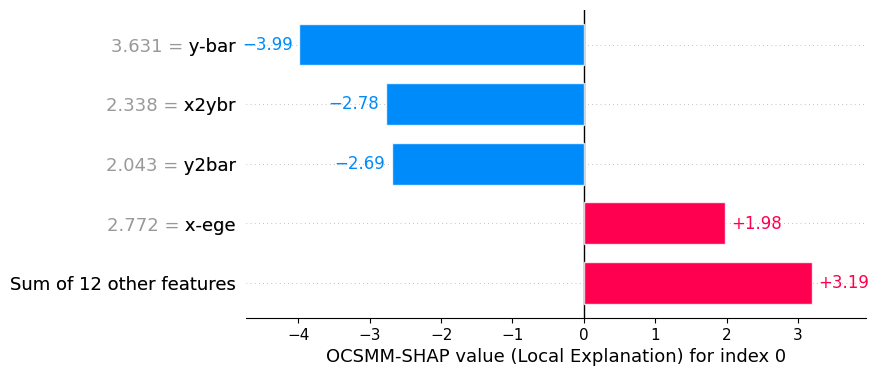

In [16]:
from src.utils.visualisation.deterministic_values import local_bar_plot_ocsmm, global_bar_plot_ocsmm
local_bar_plot_ocsmm(shapley_values.T, 0, feature_names=feature_names, datasets=datasets)

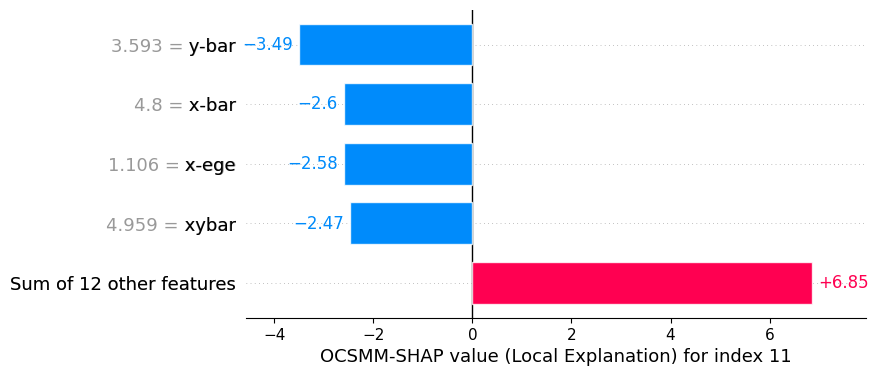

In [ ]:
local_bar_plot_ocsmm(shapley_values.T.numpy(), 11, feature_names=feature_names, datasets=datasets)

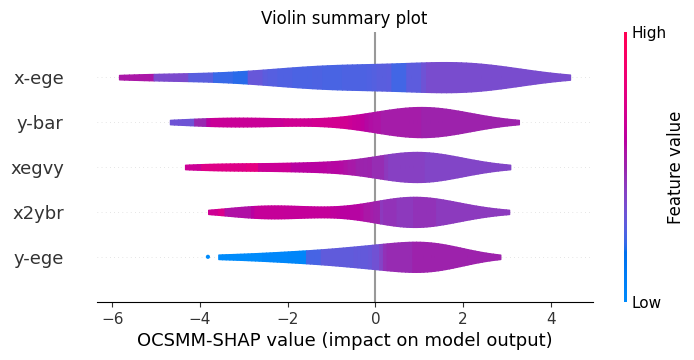

In [ ]:
from src.utils.visualisation.deterministic_values import summary_plot_ocsmm
summary_plot_ocsmm(shapley_values=shapley_values.T.numpy(), feature_names=feature_names, datasets=datasets)

/tmp/ipykernel_2672856/3584497283.py:2: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  mean_abs_shap_values = np.abs(shapley_values.T).mean(axis=0)


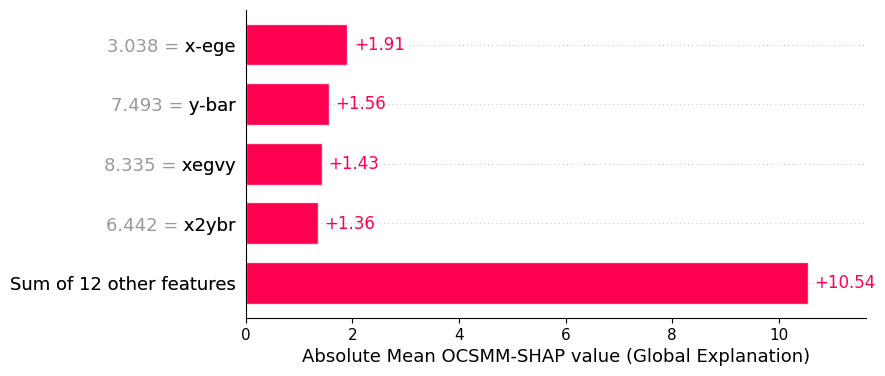

In [ ]:
# global importance measure
mean_abs_shap_values = np.abs(shapley_values.T).mean(axis=0)  

# Call bar_plot for global explanation
global_bar_plot_ocsmm(mean_abs_shap_values.numpy(), feature_names=feature_names, datasets=datasets)

In [ ]:
from src.explanation_algorithms.OCSMMSHAPIQ_Approx import OCSMMSHAPIQ, display_network_plot
shapiq = OCSMMSHAPIQ(n=len(feature_names), max_order=2, random_state=42)
interactions_per_group = shapiq.explain_single_group(
    group_data=datasets[0],
    X=datasets,  
    model=classifier,
    regularization=1e-6,
    budget=1000)

100%|██████████| 1000/1000 [04:39<00:00,  3.58it/s]


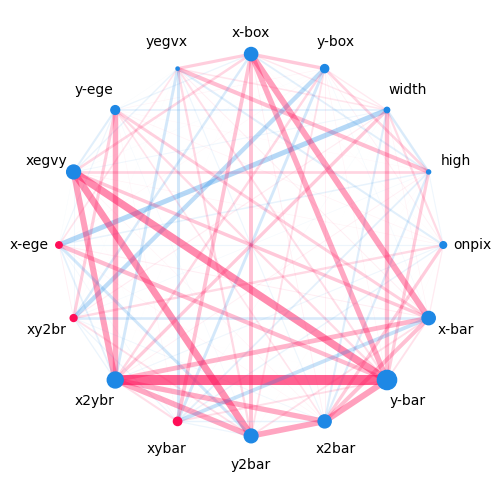

In [ ]:
display_network_plot(interactions_per_group, feature_names=feature_names)

In [17]:
shapiq = OCSMMSHAPIQ(n=len(feature_names), max_order=2, random_state=42)
interactions_per_group = shapiq.explain_single_group(
    group_data=datasets[11],
    X=datasets,  
    model=classifier,
    regularization=1e-6,
    budget=1000)

100%|██████████| 1000/1000 [04:12<00:00,  3.96it/s]


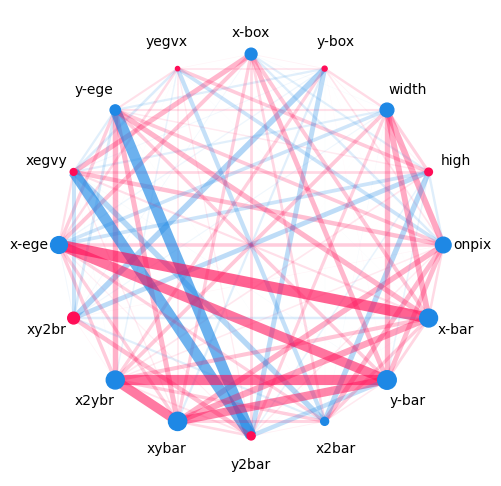

In [19]:
display_network_plot(interactions_per_group, feature_names=feature_names)

In [17]:
a_group_idx = 1  # A=0, B=1, ..., P=15, ..., Z=25
for sample in grouped_data[a_group_idx]:
    sample[0] *= 3  # Perturb x-box (feature index 0)
    sample[3] *= 4  # Perturb high(feature index 3)

In [18]:
grouped_data[1]

array([[12,  8,  6, ..., 10,  8,  9],
       [ 9,  9,  4, ...,  8,  9, 10],
       [15,  9,  7, ...,  8,  4, 12],
       ...,
       [ 6,  4,  3, ...,  8,  5,  9],
       [ 9,  3,  4, ...,  8,  9, 10],
       [15,  8,  8, ...,  8,  6, 10]], shape=(766, 16))

In [19]:
classifier = OneClassSMMClassifier(nu=0.25)

In [20]:
classifier.fit(datasets)

Best gamma found.

Kappa matrix calculated.

Found the alphas.



In [21]:
decision, y_pred = classifier.predict(datasets)

Calculating kappa.

calculating rho.

0.4274506188198471


In [22]:
decision

array([ 0.01155651, -0.11556576,  0.0115566 ,  0.09006947,  0.06852076,
        0.0229712 ,  0.09233195,  0.12087767,  0.0369936 ,  0.01155661,
        0.11321907,  0.01155652,  0.01155662,  0.08724324,  0.10099891,
        0.01155657,  0.07805649,  0.08454725,  0.07737998,  0.01155656,
        0.04949009,  0.01155658,  0.01155659,  0.12877492,  0.02370675,
        0.0115566 ])

In [23]:
y_pred

array([ 1., -1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,
        1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.])

In [24]:
outlier_indices = [i for i, value in enumerate(y_pred) if value == -1]
outlier_indices

[1]

In [25]:
ocsmm_shap = OCSMMSHAP(X=datasets, classifier=classifier, decision=decision)
ocsmm_shap.fit_ocsmmshap(X=datasets, num_coalitions=2**len(feature_names))

Calculating projections:   0%|          | 0/65535 [00:00<?, ?it/s]

Calculating projections: 100%|██████████| 65535/65535 [2:57:51<00:00,  6.14it/s]  


In [26]:
shapley_values = ocsmm_shap.return_deterministic_shapley_values()

In [27]:
import numpy as np
np.save("shapley_values_letter_after.npy", shapley_values)

In [28]:
# shapley_values = np.load("shapley_values_letter_after.npy")

In [29]:
from src.utils.visualisation.deterministic_values import local_bar_plot_ocsmm, global_bar_plot_ocsmm


In [32]:
shapley_values = shapley_values*100

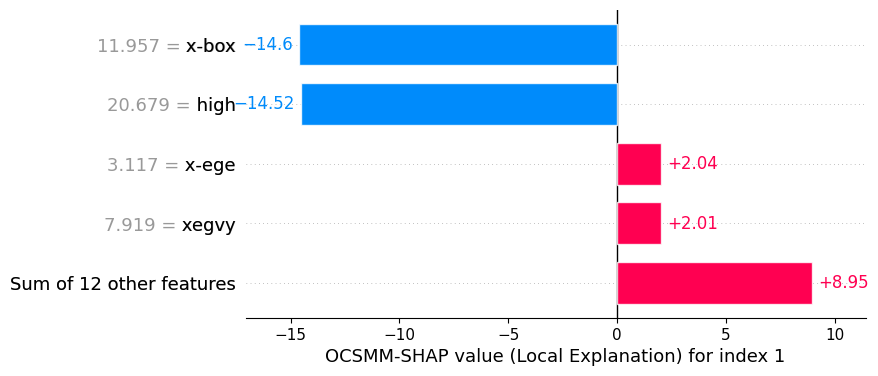

In [33]:
local_bar_plot_ocsmm(shapley_values.T.numpy(), 1, feature_names=feature_names, datasets=datasets)

/tmp/ipykernel_170641/3584497283.py:2: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  mean_abs_shap_values = np.abs(shapley_values.T).mean(axis=0)


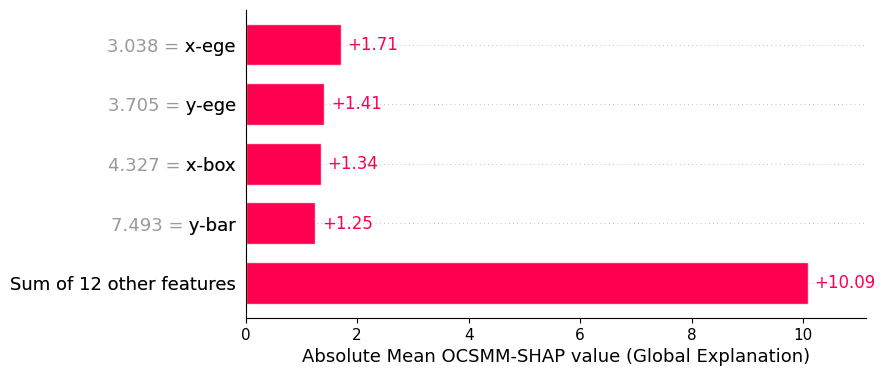

In [34]:
# global importance measure
mean_abs_shap_values = np.abs(shapley_values.T).mean(axis=0)  

# Call bar_plot for global explanation
global_bar_plot_ocsmm(mean_abs_shap_values.numpy(), feature_names=feature_names, datasets=datasets)

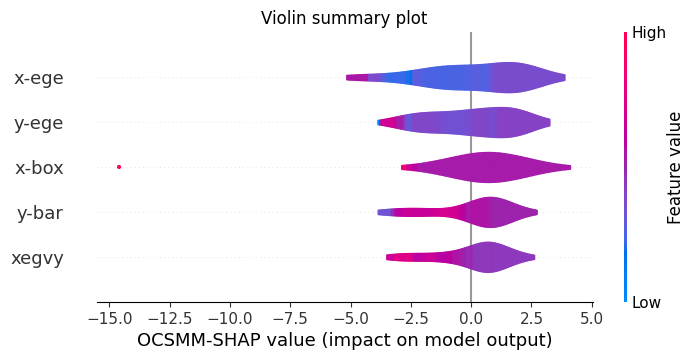

In [35]:
from src.utils.visualisation.deterministic_values import summary_plot_ocsmm
summary_plot_ocsmm(shapley_values=shapley_values.T.numpy(), feature_names=feature_names, datasets=datasets)

In [36]:
n = len(feature_names)
n

16

In [ ]:
from src.explanation_algorithms.OCSMMSHAPIQ_Approx import OCSMMSHAPIQ
shapiq = OCSMMSHAPIQ(n=16, max_order=2, random_state=42)
interactions_per_group = shapiq.explain_single_group(
    group_data=datasets[1],
    X=datasets,  
    model=classifier,
    regularization=1e-6,
    budget=1000)

  0%|          | 0/1000 [00:00<?, ?it/s]

100%|██████████| 1000/1000 [05:33<00:00,  3.00it/s]


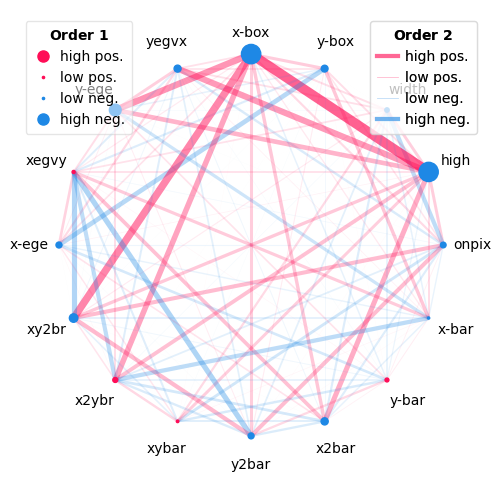

In [39]:
x = interactions_per_group.plot_network(feature_names=feature_names, show=True)

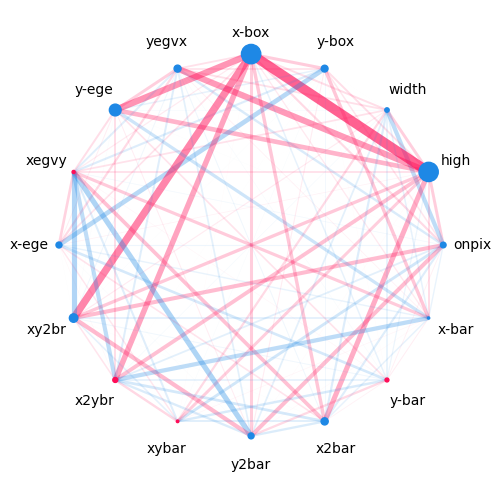

In [ ]:
from src.explanation_algorithms.OCSMMSHAPIQ_Approx import display_network_plot
display_network_plot(interactions_per_group, feature_names)